# Ground-State Energy Estimation for Early Fault-Tolerant Quantum Computers

> **Ground-state energy estimation** is one of the most important tasks in quantum computing,
> underlying quantum chemistry and condensed-matter physics. Given a Hamiltonian $H$ and an
> initial state $|\psi\rangle$ that has some overlap with the ground state $|\phi_0\rangle$, the
> goal is to estimate the ground-state energy $\lambda_0$ (the lowest eigenvalue of $H$).
>
> - **Input:** a Hamiltonian $H=\sum_j a_j P_j$ (a sum of Pauli strings) and a state-preparation
>   circuit for $|\psi\rangle$.
> - **Promise:** the ground-state overlap $p_0=|\langle\phi_0|\psi\rangle|^2$ is bounded below by a
>   *known* constant $\eta$, i.e. $p_0\ge\eta>0$.
> - **Output:** an estimate of $\lambda_0$ to additive precision $\varepsilon$, with high probability.
>
> **Complexity:** in the *oracle setting* (cost counted as the total evolution time of $e^{-i H}$, assumed to be implemented exactly) the method is *Heisenberg-limited*:
> the maximal coherent evolution time is $T_{\max}=\tilde{\mathcal{O}}(1/\varepsilon)$ (up to polylogarithmic factors), using a **single ancilla qubit**, **no inverse QFT**, and
> **no deep controlled-unitary ladders**. The bulk of the work is classical post-processing.
> In practice the evolution is only approximated (product formulas, randomized compilers), which typically **degrades the Heisenberg limit**.
>
> ---
>
> **Keywords:** Quantum phase estimation, Ground-state energy, Early fault tolerance, Single
> ancilla, Hadamard test, Heisenberg limit, Randomized
> Hamiltonian simulation.

## From textbook QPE to early fault tolerance

**Textbook QPE** [[1]](#ref-nielsen) writes the eigenphase of $U=e^{-i\tau H}$ into a quantum variable of $\sim\log(1/\varepsilon)$ qubits, using controlled powers $U^{2^j}$ and an inverse QFT
(see the [QPE notebook](https://github.com/Classiq/classiq-library/blob/main/algorithms/quantum_phase_estimation/qpe_for_matrix/qpe_for_matrix.ipynb)). It is Heisenberg-limited and pedagogically clean, but it needs many ancilla qubits and deep ladders of controlled evolutions.
**Iterative QPE** [[2]](#ref-kitaev) replaces the phase variable by a single reused ancilla, but it is limited: its adaptive, round-by-round estimates are only reliable when the initial state is already close to an eigenstate ($p_0=1$).
Several variants based on **qubitization**, such as Ref. [[3]](#ref-babbush), look promising (see the [QPE with qubitization notebook](https://github.com/Classiq/classiq-library/blob/main/algorithms/quantum_phase_estimation/qpe_with_qubitization/qpe_for_molecule_with_qubitization.ipynb)),
with the best known query complexity $\mathcal O(\|H\|_1/\varepsilon)$, where $\|H\|_1=\sum_j|a_j|$ is the normalization of the block-encoding of $H=\sum_ja_jP_j$, but they rely on a large-scale fault-tolerant regime: many logical qubits and deep controlled block-encoding circuits.
The algorithms of this notebook target the regime in between.

## The two numbers that matter

* **The target precision $\varepsilon$:** The relevant cost is the *maximal evolution time* $T_{\max}$ run coherently. Like textbook phase estimation, the methods here are **Heisenberg-limited** (in the oracle setting): $T_{\max}\sim 1/\varepsilon$, quadratically better than the standard quantum limit, where $\sim1/\varepsilon^2$ repetitions of short experiments are needed.

* **The ground-state overlap $p_0=|\langle\phi_0|\psi\rangle|^2$:** Only a **lower bound** $\eta\le p_0$ is needed (e.g. from a Hartree–Fock guess in chemistry). A small overlap does not limit the precision, but it is not free: it enters the maximal evolution time only logarithmically, $T_{\max}=\mathcal O\big(\varepsilon^{-1}\,\mathrm{polylog}(\varepsilon^{-1}\eta^{-1})\big)$, and the number of samples and the total evolution time polynomially ($\sim\eta^{-2}$) [[4]](#ref-lintong).

Therefore, $\varepsilon$ is bought with **circuit depth**, and confidence with **samples**.

## The early fault-tolerant setting and its QPE variants


Early fault-tolerant devices have real error correction but still limited resources. Lin & Tong [[4]](#ref-lintong) describe this regime as follows:

> "To be specific, we expect such early fault-tolerant quantum computers to have the following
> characteristics, (1) The number of logical qubits is limited. (2) It is undesirable to have a
> large number of controlled operations. (3) It is a priority to reduce the circuit depth, e.g., it
> is better to run a circuit of depth $O(D)$ for $O(M)$ times than to run a circuit of depth
> $O(DM)$ for a constant number of times, even if use of the shorter circuit entails some additional
> polylogarithmic factors in the total run time."

This design is common to many recent approaches (Refs. [[4]](#ref-lintong), [[5]](#ref-wbc), [[6]](#ref-gunther), [[7]](#ref-ding), and [[8]](#ref-obrien)): use a **single ancilla** and a **Hadamard test** to estimate the characteristic function
$\langle\psi|e^{-ikH}|\psi\rangle$ of the spectral measure, where $k\in \mathbb{Z}$, and extract the ground-state energy from these estimates by classical post-processing.
The post-processing differs between the approaches, as described next.


The methods in this family share the same quantum model, a single-ancilla Hadamard test of $U^k$ with $U=e^{-i\tau H}$ ($\tau$ rescales the Hamiltonian, as explained below), described in detail in the next section, and differ in two independent choices.

**(A) The statistical protocol:** which powers $k$ (and how many shots) are run, and how the outcomes are turned into $\lambda_0$.
* *Initial state close to the ground state.* Kitaev's iterative scheme [[2]](#ref-kitaev); **robust phase estimation** [[9]](#ref-kimmel), suited to a large overlap ($p_0>4-2\sqrt3\approx0.54$ [[10]](#ref-ni)); Bayesian phase estimation [[11]](#ref-wiebe) and time-series analysis [[12]](#ref-somma).
* *General (possibly small) overlap $p_0$.* Estimating the spectral Cumulative Distribution Function (CDF): Lin & Tong [[4]](#ref-lintong), with shorter circuits by Ding & Lin [[7]](#ref-ding);
  the statistical phase estimation of Wan–Berta–Campbell [[5]](#ref-wbc) rests on the same idea, and O'Brien et al. extend it to several eigenvalues [[8]](#ref-obrien).

**(B) How $U=e^{-i\tau H}$ is implemented:**
* *Deterministic* product formulas (Trotter–Suzuki).
* *Randomized* product formulas, where each shot uses a freshly sampled circuit: qDRIFT or the **randomized Taylor expansion (RTE)** [[5]](#ref-wbc).
* *Partially randomized* product formulas, which treat the large terms deterministically and the long tail of small terms randomly: Günther et al. [[6]](#ref-gunther).

---

**In this notebook.** For (A) we adopt the protocol of **Lin & Tong** [[4]](#ref-lintong), based on the CDF of the spectral measure. For (B) we first use a
deterministic Suzuki–Trotter formula on a simple model (Example 1), and then the **partially randomized** formula of Günther et al. [[6]](#ref-gunther) on an $\mathrm{H}_4$ chain (Example 2).

In [1]:
# !pip install -qq classiq["chemistry"]

Some utility functions are defined in the accompanying python files  `preprocessing.py` and `postprocessing.py`.

In [2]:
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
from postprocessing import (
    draw_shots_partition,
    exact_cdf,
    mode_distribution,
    restore_samples,
    sample_budget,
    threshold_energy,
)
from preprocessing import heaviside_coeffs_bessel, rescale_hamiltonian

from classiq import *
from classiq.open_library.functions.lcu import (  # applies a sparse Pauli string (not exported at top level)
    apply_pauli_term,
)
from classiq.qmod.builtins.enums import Pauli as PauliEnum

## The common quantum model

Every early-FT QPE method in this family queries the **same quantum object**: the characteristic function of the spectral measure of $|\psi\rangle$,
$$ g(k)=\langle\psi|U^{k}|\psi\rangle=\sum_j p_j\,e^{-ik\tau\lambda_j},\qquad U=e^{-i\tau H}\ \text{(one time step)} ,\qquad (1)$$
where $\lambda_j$ are the eigenvalues of $H$, $p_j=|\langle\phi_j|\psi\rangle|^2$, and $\tau$ rescales the Hamiltonian so that every $\tau\lambda_j$ lies in some interval $I\subset(-\pi,\pi]$ (see *Rescaling the Hamiltonian* below).
It is estimated with a **single-ancilla Hadamard test** (Figure 1; see also the [Hadamard test notebook](https://github.com/Classiq/classiq-library/blob/main/algorithms/quantum_primitives/hadamard_test/hadamard_test.ipynb)): we measure the observables $X$ and $Y$ of the ancilla, each shot returning $+1$ or $-1$, with $\mathbb E[X]=\mathrm{Re}\,g(k)$ and $\mathbb E[Y]=\mathrm{Im}\,g(k)$ [[4]](#ref-lintong). We use the `observe` call, that can returns both estimates.

![Hadamard test](figures/hadamard_test.png)

*Figure 1. The single-ancilla Hadamard test. The ancilla is rotated by $H$, controls one application of $U^k$ on $|\psi\rangle$, and the observable $X$ (or $Y$) is measured; averaging the $\pm1$ outcomes gives $\mathrm{Re}\,g(k)$ (or $\mathrm{Im}\,g(k)$).*

The Hadamard test is a single Qmod function, with the unitary supplied as an operand `u`, for the $U^k$ call. In Example 1 we simply use  every repetition as the same circuit (`power(k, step)`), whereas in Example 2 each $k$ refers to independently sampled steps when every repetition must be a *different* random circuit.

In [3]:
@qfunc
def hadamard_test(u: QCallable[QArray], state: QArray, q: QBit):
    """Single-ancilla Hadamard test for the unitary supplied as the operand `u` (applied to `state`).
    The observables X and Y of the ancilla are measured: <X> = Re <psi|U|psi>,  <Y> = Im <psi|U|psi>.
    """
    H(q)
    control(q, lambda: u(state))


def run_hadamard_pool(qprog, num_shots, params=None, verbose=True):
    """Run the Hadamard-test program and return the estimated <X> and <Y> of the ancilla (<X> = Re g, <Y> = Im g).
    `params` is an optional list of execution-parameter sets, e.g. [{"k": 1}, {"k": 3}]; verbose=False silences the job messages.
    """
    return observe(
        qprog,
        observables=[Pauli.X(0), Pauli.Y(0)],
        num_shots=num_shots,
        parameters=params,
        verbose=verbose,
    )

## The Lin & Tong [[4]](#ref-lintong) protocol for extracting the ground energy

The protocol is summarized in Figure 2: a classical set-up, a quantum stage that only runs Hadamard tests at randomly drawn powers $k$, and a classical post-processing that turns the outcomes into $\lambda_0$.
The next subsections explain the basic idea of each step, whereas the technical details are given in the original paper and appendices of this notebook.

![Protocol](figures/protocol.png)

*Figure 2. The Lin & Tong protocol. Blue boxes are classical, the orange box is the only quantum step. Step 4 can be done in several ways: this notebook uses a threshold crossing, and the paper gives a certified bisection (see* Locating the first jump *below).*

### Rescaling the Hamiltonian

As in all QPE examples, the eigenvalues of the Hamiltonian must be rescaled to lie in some interval $I\subset(-\pi,\pi]$.
Lin & Tong choose $\tau$ in Eq. (1) above such that $\tau\|H\|<\pi/3$, so $I=(-\pi/3,\pi/3)$; we call $x=\tau\lambda$ the *rescaled energy*.
The norm $\|H\|$ (the largest $|\lambda_j|$) is typically bounded by cheap estimates such as $\sum_j|a_j|$.

### The approximate cumulative distribution function (ACDF)

Let $p(x)=\sum_j p_j\,\delta(x-\tau\lambda_j)$ be the spectral measure of $|\psi\rangle$ and $C(x)=\sum_{\tau\lambda_j\le x}p_j$ its CDF: a staircase whose **first jump, at $x=\tau\lambda_0$, is the ground-state energy**; see gray curve in Fig. 3(b).
The CDF is a sum of Heaviside steps, $C(x)=\sum_jp_j\,\Theta(x-\tau\lambda_j)$. We replace the step by a smooth, band-limited filter $F(y)=\sum_{|k|\le d}\hat F_k\,e^{iky}$ that rises from $0$ to $1$ over a width of order $\delta$ around $y=0$ (Figure 3a).
The resulting **approximate CDF** (ACDF) is
$$ \tilde C(x)=\sum_jp_j\,F(x-\tau\lambda_j)=\sum_{|k|\le d}\hat F_k\,e^{ikx}\,g(k), \qquad (2)$$
a smoothed staircase (Figure 3b), written as a finite combination of exactly the numbers the Hadamard test measures (Eq. (1)).

Here $\delta$ is the *resolution* of the ACDF in rescaled energy, and a finer resolution needs more Fourier modes, $d=\mathcal O\big(\delta^{-1}\log(\delta^{-1}\eta^{-1})\big)$.
The highest mode $k=d$ is the longest evolution, so $T_{\max}\propto d\sim1/\delta$, and the energy error $\varepsilon=\delta/\tau$ falls like $1/T_{\max}$: the Heisenberg scaling.
In our implementation, we take the von Mises filter for $F$, according to Ref. [[5]](#ref-wbc) (`heaviside_coeffs_bessel` in `preprocessing.py`).

![ACDF](figures/acdf_filter.png)

*Figure 3. (a) The filter $F(y)$ for two band limits $d$: the more modes, the sharper the step. (b) The exact CDF of the TFIM of Example 1 and its approximation $\tilde C(x)$; the jump at $\tau\lambda_0$ is resolved with width $\sim\delta$.*

### Importance sampling of the Fourier modes

Measuring all the $g(k)$ costs a total evolution time $\Omega(d^2)$ (there are $\sim d$ modes, and mode $k$ needs evolution time $k$). Instead, view Eq. (2) as an expectation:
Draw $J\in\{-d,\dots,d\}$ with $\Pr[J=j]=|\hat F_j|/F$, $F=\sum_j|\hat F_j|$, run the Hadamard test at $k=J$ **once** for
$X$ and **once** for $Y$, and set $Z=X_J+iY_J\in\{\pm1\pm i\}$. Then
$$ G(x;J,Z)=F\,Z\,e^{i(\theta_J+Jx)}\quad(\theta_j=\arg\hat F_j) \quad\text{is an unbiased estimate of}\quad \tilde C(x), \qquad (3)$$
with variance $\le 2F^2$. The samples $(J_k,Z_k)$ **do not depend on $x$**: they are generated **once** and reused at every point $x$, which is how the first jump is located in the next section.

### Locating the first jump

The ground-state energy is the first jump of the CDF: $C(x)=0$ for $x<\tau\lambda_0$ and $C(x)\ge p_0\ge\eta$ afterwards (Figure 3b). We average the estimator of Eq. (3) over all the $M$ samples, which gives $\bar G(x)$, and take the first point where it crosses a threshold:
$$ x^\star=\min\big\{x:\ \bar G(x)\ge\tfrac34\eta\big\},\qquad \tilde\lambda_0=x^\star/\tau. \qquad (4)$$
This is the simple estimator that Lin & Tong use in their numerical experiments (Sec. 3 and Appendix F of Ref. [[4]](#ref-lintong), with the threshold $\eta/2$).
When the filter resolves the jump (the band limit $d$ of the theory), any threshold between $\eta/4$ and $\tfrac34\eta$ is a reasonable heuristic for finding $|x^\star-\tau\lambda_0|\le\delta$. Ref. [[4]](#ref-lintong) also provides a certified search protocol, that gives a guaranteed error and a rigorous confidence level (see INVERT CDF and CERTIFY, Algorithms 1 and 2 in Sec. 5; Theorem 2). We do not implement it here, instead the function `threshold_energy` in `postprocessing.py` evaluates $\bar G$ on a grid of spacing $\delta/10$ and returns the first crossing according to Eq. (4).

## Example 1: Suzuki–Trotter evolution on a TFIM Hamiltonian

As a simple demonstration we take a 2-qubit **transverse-field Ising model** (TFIM),
$$
H=-J\,Z_0Z_1-g\,(X_0+X_1).
$$

In [4]:
EPS_HA = 0.01  # target precision, delta = EPS_HA * scale in the rescaled units

J, g = 1.0, 0.5
HAM = -J * Pauli.Z(0) * Pauli.Z(1) - g * (Pauli.X(0) + Pauli.X(1))

For the Hamiltonian evolution $U=e^{-i\tau H}$, we take a deterministic second-order **Suzuki–Trotter** product formula.
The spectrum is first scaled, $H\mapsto\tau H$, so that it lies inside the $(-\pi/3,\pi/3)$
window the Fourier series needs (`rescale_hamiltonian`, see *Rescaling the Hamiltonian*). We take $\tau=0.9\,\tfrac{\pi}{3}\big/\|H\|$, with the norm $\|H\|$ (the largest $|\lambda_j|$) taken from the exact spectrum.

We calculate the exact system of eigenstates and eigenvalues for a reference. In particular, we take some bound $\eta$ according to the actual overlap $p_0$.

> **Note:** We choose specifically $\eta\approx\tfrac23p_0$, that fits well the threshold of $3\eta / 4$ in Eq. (4). This is necessary since, as described below, we also take a relaxed value for the number of samples and the degree $d$. Of-course that in practice, one does not have access to $p_0$, and needs to run a non-relaxed scheme according to the rigorous theory.

In [5]:
evals_tfim, evecs_tfim = np.linalg.eigh(hamiltonian_to_matrix(HAM))
gs_true_tfim = evals_tfim[0]
ham_tfim, scale_tfim, unscale_tfim = rescale_hamiltonian(HAM, abs(evals_tfim).max())
evs_tfim = evals_tfim * scale_tfim
delta_tfim = (
    EPS_HA * scale_tfim
)  # target precision in rescaled energy: epsilon = delta / tau

psi_tfim = np.array(
    [1, 0, 0, 0], dtype=complex
)  # |00>: partial overlap with every eigenstate
p_tfim = np.abs(evecs_tfim.conj().T @ psi_tfim) ** 2  # exact overlap, reference only
print(
    "true ground-state energy:",
    round(gs_true_tfim, 6),
    "| overlap p0 =",
    round(p_tfim[0], 4),
)

ETA_TFIM = 0.28
assert ETA_TFIM < p_tfim[0]
print(f"actual eta taken: eta={ETA_TFIM}<{round(p_tfim[0],4)}")

true ground-state energy: -1.414214 | overlap p0 = 0.4268
actual eta taken: eta=0.28<0.4268


Now, given the overlap bound $\eta$ (`ETA_TFIM`) and the accuracy $\varepsilon$ (`EPS_HA`) we can calculate the degree $d$ of the ACDF in Eq. (2). After the rescaling the resolution is $\delta=\varepsilon\tau$, and the paper requires $d=\mathcal O\big(\delta^{-1}\log(\delta^{-1}\eta^{-1})\big)$. For the demonstration, we take a relaxed value for $d$ (`D_TFIM`).

We then calculate the filter coefficients $\{F_j\}^{d}_{j=0}$. The filtering function has a $\beta$ parameter that we fix to $\beta=d^2/10$ (we have verified numerically that it gives a step of width $\approx4/d$ with negligible ringing).

In [6]:
# Protocol parameters: what the theory asks for, and the relaxed values we use
d_theory = int(
    np.ceil(np.log(1 / (delta_tfim * ETA_TFIM)) / delta_tfim)
)  # paper: d = O(delta^-1 log(delta^-1 eta^-1)); we take the constant 1
D_TFIM = 60  # relaxed band limit d (for shorter runtime)
beta_tfim = D_TFIM**2 / 10  # a control parameter for the filter function
print(
    f"theory: d ~ {d_theory} for eta ~ {ETA_TFIM:.2f}   |   used (relaxed): d = {D_TFIM}, beta = {beta_tfim:.0f}"
)
fhat_tfim = heaviside_coeffs_bessel(D_TFIM, beta_tfim)

theory: d ~ 943 for eta ~ 0.28   |   used (relaxed): d = 60, beta = 360


For the powered evolution we use the Suzuki–Trotter formula with `power(k, ...)`, which composes $k$ identical steps. The model is synthesized
**once**, and $k$ is swept at execution time. We take formula of order 2, and estimate the number of repetitions per step $r$ from the error bound of Hagan & Wiebe [[13]](#ref-hagan), as explained in the
[QPE for molecules notebook](https://github.com/Classiq/classiq-library/blob/main/applications/chemistry/qpe_for_molecules/qpe_for_molecules.ipynb).
This bound controls the **diamond-norm** distance between the Trotter step and $U$. Phase estimation needs less: the Trotter step is exactly $e^{-i\tilde H_{\rm eff}}$ for an effective Hamiltonian $\tilde H_{\rm eff}$, and what matters is the difference between the ground-state energies of $\tilde H_{\rm eff}$ and $\tilde H$, a fixed shift that does not grow with $k$ [[6]](#ref-gunther).
The bound is therefore a worst case, so we divide it by a safety factor (for this small problem we can verify it is OK, see Appendix B).

In [7]:
from itertools import product

TROTTER_ORDER = 2  # our choice


def reps_from_err_bound(hamiltonian, error_bound, t=1.0):
    """Repetitions r of the order-2 Suzuki-Trotter formula that approximate e^{-i t H} to diamond-norm error `error_bound`
    (Hagan & Wiebe):  r >= (2^5 gamma_2 / (3 eps))^(1/2) t^(3/2),
    gamma_2 = sum_{l,m,n} |a_l a_m a_n| ||[P_l,[P_m,P_n]]||, bounded with the triangle inequality over the Pauli terms
    (each Pauli string has unit norm)."""
    terms = [
        SparsePauliOp(terms=[term], num_qubits=hamiltonian.num_qubits)
        for term in hamiltonian.terms
    ]
    gamma_2 = sum(
        sum(
            abs(term.coefficient)
            for term in commutator(P_l, commutator(P_m, P_n)).terms
        )
        for P_l, P_m, P_n in product(terms, repeat=3)
    )
    return np.sqrt(2**5 * gamma_2 / (3 * error_bound)) * t**1.5


reps_bound = reps_from_err_bound(
    ham_tfim, delta_tfim
)  # one step U = e^{-i tau H} (t = 1); the target precision in rescaled units
TROTTER_REPS_SAFETY = (
    25  # our choice: the bound is a worst case and far from tight (see Appendix B)
)
trotter_reps = int(np.ceil(reps_bound / TROTTER_REPS_SAFETY))
print(
    f"bound: {reps_bound:.1f} repetitions;  divided by {TROTTER_REPS_SAFETY}  ->  trotter_reps = {trotter_reps}"
)

bound: 87.1 repetitions;  divided by 25  ->  trotter_reps = 4


In [8]:
@qfunc
def trotter_step(state: QArray[QBit]):
    """One step U = e^{-i H~}, second-order Suzuki-Trotter."""
    suzuki_trotter(ham_tfim, 1.0, TROTTER_ORDER, trotter_reps, state)


@qfunc
def main(k: CInt, q: Output[QBit]):
    state = QArray()
    allocate(ham_tfim.num_qubits, state)  # |psi> = |0...0>
    allocate(q)
    hadamard_test(lambda s: power(k, lambda: trotter_step(s)), state, q)
    drop(state)


qprog_tfim = synthesize(main)
show(qprog_tfim)

Quantum program link: https://platform.classiq.io/circuit/3LMJRSO8y1c5CRMs9iYjqHLKhfM


### Number of samples

The threshold estimate of Eq. (4) is guaranteed to land within $\delta$ of $\tau\lambda_0$ if two errors are each smaller than $\eta/8$: the smoothing error of the filter, $|\tilde C-C|$, which sets the band limit $d$ (as in Sec. 5 of Ref. [[4]](#ref-lintong)), and the sampling error $|\bar G-\tilde C|$ at every point of the search grid. The second condition sets the number of samples (see derivation in Appendix D):
$$ M\ \ge\ \frac{256A^2}{\eta^2}\,\ln\frac{2n_{\rm grid}}{\vartheta}, $$
where $A=\sum_{k\ne0}|\hat F_k|$ is the scale of the estimator, $n_{\rm grid}$ is the number of points of the search grid, and $\vartheta$ is the failure probability (we take $\vartheta=5\%$). The function `sample_budget` in `postprocessing.py` evaluates this bound.
Since $A=\mathcal O(\log d)$ and $n_{\rm grid}\propto\delta^{-1}$, it scales as $M=\mathcal O\big(\eta^{-2}\log^2d\,\log(\delta^{-1}\vartheta^{-1})\big)$.

We start by calling the function `mode_distribution` (in `postprocessing.py`), which returns the array of possible $k$ values and the probability to sample each of them, according to Eq. (3). Then `draw_shots_partition` draws the $M$ modes and returns $n_k$, the number of shots needed at each power $k$.

In [9]:
rng = np.random.default_rng(0)
k_array_tfim, pk_tfim, A_tfim = mode_distribution(fhat_tfim)

# Number of samples: worst-case theory (with the theoretical band limit d_theory) vs. the relaxed value we use
_, _, A_theory = mode_distribution(heaviside_coeffs_bessel(d_theory, d_theory**2 / 10))
M_theory = sample_budget(A_theory, ETA_TFIM, delta_tfim)
M = 20000  # relaxed (our choice)
print(f"theory: M = {M_theory}   |   used (relaxed): M = {M}")
n_k_tfim = draw_shots_partition(
    rng, k_array_tfim, pk_tfim, M
)  # n_k_tfim[i]: number of draws of k_array_tfim[i]

mean_k = np.sum(k_array_tfim * pk_tfim)
std_k = np.sqrt(np.sum(pk_tfim * (k_array_tfim - mean_k) ** 2))
print(
    f"{M} samples;  {int((n_k_tfim > 0).sum())} distinct odd k values;  "
    f"typical sampled k ~ {np.round(mean_k,4)} with variance {np.round(std_k,4)} (bounded by D = {D_TFIM})"
)

theory: M = 227127   |   used (relaxed): M = 20000
20000 samples;  30 distinct odd k values;  typical sampled k ~ 8.6161 with variance 11.6548 (bounded by D = 60)


### Running the samples efficiently

The protocol needs $M$ samples, each a single shot at a random $k$. All the shots at one $k$ are i.i.d., so we do not run them one by one: we run **one pool of shots per distinct $k$** (the same synthesized circuit with $k$ as an execution parameter).
A common pool size $S=\max_kn_k$ lets `observe` run all the $k$'s in a single call, and from the pool of each $k$ we keep a random subset of the $n_k$ shots it needs (a hypergeometric draw, `restore_samples` in `postprocessing.py`), which is statistically identical to one shot per sample. The idea here is to take extra shots (which are free on a simulator, but not on hardware), but still extract the ACDF according to the designed protocol.

In [10]:
# oversample: the same number S of shots at every drawn k
used_tfim = n_k_tfim > 0  # indicates the k values that need to be sampled
S_tfim = int(n_k_tfim.max())
pool_x, pool_y = run_hadamard_pool(
    qprog_tfim, S_tfim, [{"k": int(k)} for k in k_array_tfim[used_tfim]]
)  # ONE call
mean_x, mean_y = np.zeros(len(k_array_tfim)), np.zeros(
    len(k_array_tfim)
)  # pool means, aligned with k_array
mean_x[used_tfim], mean_y[used_tfim] = pool_x, pool_y
print(
    f"pool: {int(used_tfim.sum())} values of k, {S_tfim} shots each (the samples need {M} in total)"
)

Submitting job to simulator
Job: https://platform.classiq.io/jobs/3eca0c32-779e-469f-b86c-6f101250b386


pool: 30 values of k, 8041 shots each (the samples need 20000 in total)


Now, given the pooled results (the mean outcomes at each $k$, from $S$ shots each), we restore the samples: from the pool of each $k$ we keep the $n_k$ shots it requires, using `restore_samples`. Then we locate the first crossing of $\tfrac34\eta$, Eq. (4), with `threshold_energy`.

In [11]:
# keep exactly the n_k outcomes that each k needs from its pool
sums_x = restore_samples(
    rng, n_k_tfim, mean_x, S_tfim
)  # sums_x[i] = sum of the +-1 X outcomes at k_array_tfim[i]
sums_y = restore_samples(rng, n_k_tfim, mean_y, S_tfim)

In [12]:
x_star, G_tfim = threshold_energy(
    sums_x, sums_y, k_array_tfim, A_tfim, M, 0.75 * ETA_TFIM, delta_tfim
)
gs_tfim = unscale_tfim(x_star)
print(
    f"Lin-Tong ground-state energy: {gs_tfim:.4f}  (err {abs(gs_tfim - gs_true_tfim):.4f}, target {EPS_HA})"
)
print(f"true ground-state energy:     {gs_true_tfim:.4f}")

Lin-Tong ground-state energy: -1.4103  (err 0.0039, target 0.01)
true ground-state energy:     -1.4142


Finally, we can plot the resulting ACDF, compared to the reference CDF and the extracted ground state energy:

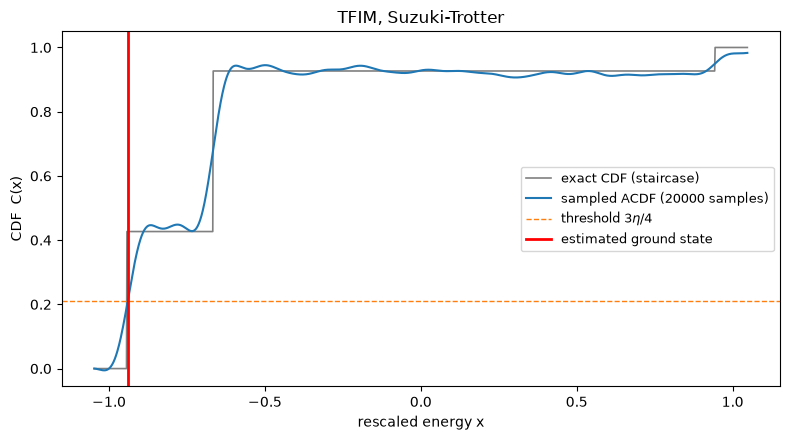

In [13]:
xgrid = np.linspace(-np.pi / 3, np.pi / 3, 1500)
plt.figure(figsize=(8, 4.5))
plt.plot(
    xgrid,
    exact_cdf(xgrid, evs_tfim, p_tfim),
    color="grey",
    lw=1.2,
    label="exact CDF (staircase)",
)
plt.plot(xgrid, G_tfim(xgrid), "C0-", lw=1.5, label=f"sampled ACDF ({M} samples)")
plt.axhline(0.75 * ETA_TFIM, color="C1", ls="--", lw=1, label=r"threshold $3\eta/4$")
plt.axvline(x_star, color="red", lw=2, label="estimated ground state")
plt.xlabel("rescaled energy x")
plt.ylabel("CDF  C(x)")
plt.title("TFIM, Suzuki-Trotter")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Example 2: partially randomized evolution with a randomized Taylor tail (Günther et al.)

### The quantum model

The quantum model is again the Hadamard test of $U^k$, but now $U^k$ is **not** $k$ copies of one circuit. It is a product of $k/\zeta$ **independently
sampled** random steps,
$$ U^k\ \longrightarrow\ W_k=S^{(k/\zeta)}(\zeta)\cdots S^{(2)}(\zeta)\,S^{(1)}(\zeta), $$
where each step $S(\zeta)$ approximates the evolution $e^{-i\zeta\tilde H}$ for a time $\zeta=$`ZETA`, with $\zeta=1/m$ for an integer $m$, so that every $U$ is made of $m$ steps.
A smaller $\zeta$ gives a finer Trotter splitting of the deterministic part (below) at the price of deeper circuits. The value of $\zeta$ should follow from the Trotter error of $S(\zeta)$, i.e., the shift of the ground-state energy of its effective Hamiltonian, by a calculation as the one we did for the TFIM in Example 1. We do not perform this calculation here, and simply take $\zeta=1$, i.e., one step per $U$, which we found to be sufficient.
The Hamiltonian $\tilde H=\tau H=\sum_j\tilde a_jP_j$ is the rescaled Hamiltonian of the sections above, with $\tilde a_j=\tau a_j$, and $U=e^{-i\tilde H}$.

Following **Günther et al.** [[6]](#ref-gunther), split $\tilde H=\tilde H_D+\tilde H_R$ into a **deterministic head** $\tilde H_D=\sum_{l\le L_D}\tilde a_lP_l$
(the $L_D$ largest-$|\tilde a_l|$ Pauli terms, evolved as a symmetric Trotter sandwich) and a **randomized tail** $\tilde H_R=\sum_{l>L_D}\tilde a_lP_l=\lambda_R\sum_l \pi_lQ_l$,
with $\lambda_R=\sum_{l>L_D}|\tilde a_l|$, $\pi_l=|\tilde a_l|/\lambda_R$ (a probability distribution over the tail terms) and $Q_l=\mathrm{sign}(\tilde a_l)P_l$:
$$ S(\zeta)=e^{-\frac i2\zeta\tilde a_1P_1}\cdots e^{-\frac i2\zeta\tilde a_{L_D}P_{L_D}}\;\;e^{-i\zeta\tilde H_R}\;\;e^{-\frac i2\zeta\tilde a_{L_D}P_{L_D}}\cdots e^{-\frac i2\zeta\tilde a_1P_1}
   \qquad (5) .$$
The many small terms of the tail never need their own Trotter factor. They are implemented with the **Randomized Taylor expansion (RTE)** [[5]](#ref-wbc), as we describe next:

Write $e^{-i\zeta\tilde H_R}=(e^{-i\theta\bar Q})^r$ with $\bar Q=\sum_l\pi_lQ_l$ and
$\theta=\zeta\lambda_R/r$. One round, with even orders $n$ only [[5]](#ref-wbc)-[[6]](#ref-gunther), expands as
$$ e^{-i\theta\bar Q}=\sum_{n\ \mathrm{even}}\underbrace{\frac{\theta^n}{n!}\sqrt{1+\tfrac{\theta^2}{(n+1)^2}}}_{c_n}\sum_{l,l_1..l_n}\pi_l\pi_{l_1}\!\cdots \pi_{l_n}\;
   (-1)^{n/2}\,e^{-i\varphi_nQ_l}\,Q_{l_n}\!\cdots Q_{l_1},\qquad \varphi_n=\arctan\tfrac{\theta}{n+1}, \qquad (6)$$
Every term is a unitary with a positive weight, so a round is **sampled** in two steps:
1. **The order:** draw an even $n$ with probability $c_n/B(\theta)$, where $B(\theta)=\sum_nc_n\le e^{\theta^2}$ [[6]](#ref-gunther).
2. **The terms:** draw $n+1$ indices $l_1,\dots,l_n$ and $l$, each independently from the distribution $\pi$ (so terms with larger $|\tilde a_l|$ are drawn more often). The first $n$ give the Pauli product $Q_{l_n}\cdots Q_{l_1}$ and the last gives the rotation $e^{-i\varphi_nQ_l}$.

The Hadamard test on a sampled circuit $W_k$ gives $\mathbb E[Z]=g(k)/B_k$, an **unbiased** estimator of $g(k)$ after multiplying by $B_k=B(\theta)^{rk/\zeta}$. The price is variance, as samples scale by $B_k$.

### A specific usecase: an $\mathrm{H}_4$ chain

The Hamiltonian is that of a linear hydrogen chain of four atoms at equal spacing of 1.4 Bohr (the benchmark geometry of Günther et al.), in the minimal STO-6G basis, with a Jordan–Wigner map: 8 qubits, and the Hartree–Fock state has a ground-state overlap close to 1.
We reduce the problem with **qubit tapering**: the Hamiltonian has $\mathbb Z_2$ symmetries (such as the parities of the numbers of spin-up and spin-down electrons), and `Z2SymTaperMapper` fixes them to the sector of the Hartree–Fock state and removes one qubit per symmetry.
The ground state lies in this sector, so its energy is unchanged, while the qubits drop from 8 to 5 and the Pauli terms from 185 to 132, which shortens every circuit below.

In [14]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf

from classiq.applications.chemistry.hartree_fock import get_hf_state
from classiq.applications.chemistry.mapping import FermionToQubitMapper
from classiq.applications.chemistry.op_utils import qubit_op_to_qmod
from classiq.applications.chemistry.problems import FermionHamiltonianProblem
from classiq.applications.chemistry.z2_symmetries import Z2SymTaperMapper

BOND_LENGTH = 1.4 * 0.529177  # Angstrom (1.4 Bohr)
molecule_H4_geometry = [("H", (0.0, 0.0, i * BOND_LENGTH)) for i in range(4)]

basis = "sto-6g"  # Basis set
multiplicity = 1  # Singlet state S=0
charge = 0  # Neutral molecule
molecule = MolecularData(molecule_H4_geometry, basis, multiplicity, charge)
molecule = run_pyscf(molecule, run_fci=True)

problem = FermionHamiltonianProblem.from_molecule(molecule=molecule)
jw_ham = FermionToQubitMapper().map(
    problem.fermion_hamiltonian
)  # Jordan-Wigner, before tapering
mapper = Z2SymTaperMapper.from_problem(problem)  # sector of the Hartree-Fock state
mol_ham = qubit_op_to_qmod(mapper.map(problem.fermion_hamiltonian))
num_qubits_h4 = mapper.get_num_qubits(problem)
hf_state = get_hf_state(problem, mapper)
print(
    f"Jordan-Wigner: {FermionToQubitMapper().get_num_qubits(problem)} qubits, {len(jw_ham.terms)} Pauli terms  ->  "
    f"tapered: {num_qubits_h4} qubits, {len(mol_ham.terms)} Pauli terms;  FCI energy: {molecule.fci_energy:.4f} Ha"
)

Jordan-Wigner: 8 qubits, 185 Pauli terms  ->  tapered: 5 qubits, 132 Pauli terms;  FCI energy: -2.1574 Ha


We rescale the Hamiltonian as in Example 1, and calculate the exact eigenstates and eigenvalues for a reference. The initial state is the Hartree–Fock state, and as before we take a bound $\eta$ according to the actual overlap $p_0$:

In [15]:
n_q = num_qubits_h4
evals_h4, evecs_h4 = np.linalg.eigh(hamiltonian_to_matrix(mol_ham))
gs_true_h4 = evals_h4[0]
ham_h4, scale_h4, unscale_h4 = rescale_hamiltonian(mol_ham, abs(evals_h4).max())
psi_h4 = np.zeros(2**n_q, dtype=complex)
psi_h4[sum(1 << q for q, occ in enumerate(hf_state) if occ)] = (
    1.0  # Hartree-Fock basis state (qubit 0 = LSB)
)
p_h4 = np.abs(evecs_h4.conj().T @ psi_h4) ** 2  # exact overlaps, reference only
evs_h4 = evals_h4 * scale_h4
delta_h4 = EPS_HA * scale_h4  # target precision in rescaled energy
print(
    f"H4 chain: {n_q} qubits, true ground energy {gs_true_h4:.4f} Ha, HF overlap p0 = {p_h4[0]:.3f}"
)

ETA_H4 = 0.65
assert ETA_H4 < p_h4[0]
print(f"actual eta taken: eta={ETA_H4}<{round(p_h4[0], 4)}")

H4 chain: 5 qubits, true ground energy -2.1574 Ha, HF overlap p0 = 0.974
actual eta taken: eta=0.65<0.974


Now, given the overlap bound $\eta$ (`ETA_H4`) and the accuracy $\varepsilon$ (`EPS_HA`), we calculate the parameters of the algorithm as in Example 1: The band limit $d$ and the number of samples $M$. As before, for $\varepsilon=0.01$ Ha the theoretical values are far beyond what is needed for a demonstration (compare the printed value with the one we use), so we use **relaxed** values for $d$ and $M$.

In [16]:
# Protocol parameters: what the theory asks for, and the relaxed values we use
d_theory_h4 = int(
    np.ceil(np.log(1 / (delta_h4 * ETA_H4)) / delta_h4)
)  # d = O(delta^-1 log(delta^-1 eta^-1))
D_H4 = 18  # relaxed band limit d (our choice, for runtime)
beta_h4 = D_H4**2 / 10  # our choice, as in Example 1
fhat_h4 = heaviside_coeffs_bessel(D_H4, beta_h4)
k_array_h4, pk_h4, A_h4 = mode_distribution(fhat_h4)

_, _, A_theory_h4 = mode_distribution(
    heaviside_coeffs_bessel(d_theory_h4, d_theory_h4**2 / 10)
)
M_theory_h4 = sample_budget(
    A_theory_h4, ETA_H4, delta_h4
)  # worst-case number of samples, with the theoretical d
M_H4 = 50000  # relaxed number of samples (our choice)
print(
    f"theory: d ~ {d_theory_h4}, M = {M_theory_h4}   |   used (relaxed): d = {D_H4}, beta = {beta_h4:.0f}, M = {M_H4}"
)

theory: d ~ 3603, M = 64531   |   used (relaxed): d = 18, beta = 32, M = 50000


Next to the **core idea of Günther et al [[6]](#ref-gunther)**, splitting the rescaled Hamiltonian $\tilde H$ into the head $\tilde H_D$ (the `N_DET` terms of largest $|\tilde a_l|$) and the tail $\tilde H_R$, with $\lambda_R$ the $\ell_1$ norm of the tail coefficients. The identity term of $\tilde H$ is a global phase, so it is dropped from the circuit and its coefficient `c_I` is kept aside.
The number of random terms (RTE rounds) per step $r=$`R_TAIL` is discussed below (see the section on depth, samples and random circuits), and $\theta=\zeta\lambda_R/r$ is the resulting RTE step. The step time `ZETA` must be $1/m$ for an integer $m$ (`STEPS_PER_U`$=m$ steps per $U$).

In [17]:
from preprocessing import partition_hamiltonian, to_sparse_op

N_DET = 79  # number of largest-|coefficient| terms evolved deterministically (we take ~60% of the terms)
ZETA = 1.0  # time of one elementary step S(zeta); must be 1/m for an integer m (1 is sufficient for our example)
R_TAIL = 4  # random terms (RTE rounds) per step: depth vs samples, and how well one random circuit represents the average (see below)

STEPS_PER_U = round(1 / ZETA)  # m steps S(zeta) make one U = e^{-i \tau H}
assert np.isclose(STEPS_PER_U * ZETA, 1.0), "ZETA must be 1/m for an integer m"

head, tail, lam_R, c_I = partition_hamiltonian(ham_h4, n_q, N_DET)
theta = ZETA * lam_R / R_TAIL
print(
    f"partition: {len(head)} deterministic + {len(tail)} randomized-tail terms (lambda_R = {lam_R:.3f});\n"
    f"{STEPS_PER_U} step(s) per U, r = {R_TAIL} RTE rounds/step, theta = {theta:.4f};\n"
    f"B_D - 1 ~ D zeta lam_R^2/r = {D_H4 * ZETA * lam_R**2 / R_TAIL:.3f}"
)

partition: 79 deterministic + 53 randomized-tail terms (lambda_R = 0.141);
1 step(s) per U, r = 4 RTE rounds/step, theta = 0.0353;
B_D - 1 ~ D zeta lam_R^2/r = 0.090


### The classical RTE sampler

`rte_distribution` returns the orders $n$, their probabilities $c_n/B$ and the constant $B(\theta)$ (truncated at `N_RTE_MAX`);
`sample_tail` draws one tail evolution $e^{-i\zeta\tilde H_R}$ as `R_TAIL` rounds $(n,[l_1..l_n],l)$.

In [18]:
N_RTE_MAX = 4  # RTE Taylor order truncation (orders 0, 2, ..., N_RTE_MAX. Higher orders are deep and have negligible weight)

tail_p = np.array([abs(c) for c, _ in tail]) / lam_R  # pi_l
tail_sign = np.array([np.sign(c) for c, _ in tail])  # Q_l = sign * P_l


def rte_distribution(theta, n_max=N_RTE_MAX):
    """Orders n = 0, 2, .., n_max, their probabilities c_n / B and the normalization B(theta) = sum_n c_n."""
    ns = np.arange(0, n_max + 1, 2)
    c = np.array(
        [theta**n / factorial(n) * np.sqrt(1 + theta**2 / (n + 1) ** 2) for n in ns]
    )
    return ns, c / c.sum(), c.sum()


rte_orders, rte_probs, b_round = rte_distribution(theta)


def sample_tail(rng):
    """One random tail evolution e^{-i zeta H~_R}: R_TAIL RTE rounds, each (n, [l_1..l_n], l)."""
    rounds = []
    for _ in range(R_TAIL):
        n = int(rng.choice(rte_orders, p=rte_probs))
        ls = rng.choice(len(tail), size=n + 1, p=tail_p)
        rounds.append((n, list(ls[:n]), int(ls[n])))
    return rounds


def B_k(k):
    """Normalization of U^k = k * STEPS_PER_U sampled steps of R_TAIL rounds each: E[Z] = g(k) / B_k."""
    return b_round ** (R_TAIL * k * STEPS_PER_U)


print(
    f"P(order n) = {dict(zip(rte_orders.tolist(), np.round(rte_probs, 5).tolist()))},  B(theta) = {b_round:.5f},  B_D = {B_k(D_H4):.4f}"
)

P(order n) = {0: 0.99938, 2: 0.00062, 4: 0.0},  B(theta) = 1.00124,  B_D = 1.0936


We can see that order $n=0$ is almost dominating completely the distribution. This order is identical to the qDRIFT scheme.

### The quantum function: $k$ sampled steps

The sampled tail enters the model as **classical arrays**, one row per RTE round, and the loops over steps and rounds are Qmod
`repeat`s, so every sampled circuit is the *same* compact Qmod program with different data (`partial_evolution`, built from `rte_round`). Inside the Hadamard test's `control`:

* head: a first-order Trotter sweep `suzuki_trotter(head_op, ζ/2, 1, 1)`, and after the tail the same sweep in reversed order, `invert(suzuki_trotter(head_op, -ζ/2, 1, 1))`, giving a symmetric sandwich;
* tail round $(n,[l_1..l_n],l)$ (`rte_round`): the strings $Q_{l_1},\dots,Q_{l_n}$ multiply to **one** Pauli string times a scalar, obtained with
  `SparsePauliOp` arithmetic (`clifford_product`) and applied with `apply_pauli_term`; then $e^{-i\varphi_n Q_l}$ with `single_pauli_exponent`;
* the remaining scalar is a **relative phase** once controlled, applied with `phase`.

The Hartree–Fock reference is prepared with `prepare_basis_state`.

In [19]:
head_op = to_sparse_op(head, n_q)  # the deterministic head as a SparsePauliOp


@qfunc
def rte_round(
    idx: CInt,
    cliff: CArray[CArray[IndexedPauli]],
    rot: CArray[CArray[Pauli]],
    angles: CArray[CReal],
    phases: CArray[CReal],
    target: QArray[QBit],
):
    """Sampled RTE round number idx: the product of its Clifford strings Q_{l_n}...Q_{l_1} (one Pauli string; identity
    when n = 0), the Pauli rotation exp(-i phi_n Q_l), and the remaining scalar phase (the (-1)^{n/2}, the signs of the
    Q's and the factors of i from multiplying Paulis), which is a relative phase once controlled.
    """
    apply_pauli_term(cliff[idx], target)
    single_pauli_exponent(rot[idx], angles[idx], target)
    phase(phases[idx])


@qfunc
def partial_evolution(
    n_steps: CInt,
    cliff: CArray[CArray[IndexedPauli]],
    rot: CArray[CArray[Pauli]],
    angles: CArray[CReal],
    phases: CArray[CReal],
    target: QArray[QBit],
):
    """n_steps sampled partially randomized steps S(zeta): a first-order Trotter sweep over the head, the R_TAIL sampled
    RTE rounds of the tail, and the head sweep again in reversed order (a symmetric sandwich).
    """

    def step(s):
        suzuki_trotter(head_op, ZETA / 2, 1, 1, target)
        repeat(
            R_TAIL,
            lambda j: rte_round(s * R_TAIL + j, cliff, rot, angles, phases, target),
        )
        invert(
            lambda: suzuki_trotter(head_op, -ZETA / 2, 1, 1, target)
        )  # the same sweep in reversed order

    repeat(n_steps, step)


tail_ops = [
    to_sparse_op([(float(np.sign(c)), dense)], n_q) for c, dense in tail
]  # Q_l = sign(h_l) P_l, as SparsePauliOps


def clifford_product(ls):
    """Q_{l_n} ... Q_{l_1} (Q_{l_1} acts first) with SparsePauliOp arithmetic.  The product of Pauli strings is again one Pauli
    string, times a scalar (the signs of the Q's and a power of i); it is returned as a single SparsePauliTerm.
    """
    prod = Pauli.I(0)
    for l in ls:
        prod = tail_ops[l] * prod
    return prod.terms[0]


def encode_steps(steps):
    """Flatten the sampled steps (lists of rounds (n, [l_1..l_n], l)) into the classical arrays of the Qmod program: one sparse
    Clifford string per round (the product of its Q's), the rotation string, its angle and the scalar phase.
    """
    cliff, rot, angles, phases = [], [], [], []
    for rounds in steps:
        for n, ls, l in rounds:
            term = clifford_product(ls)
            cliff.append(
                [q for q in term.paulis if q.pauli != PauliEnum.I] or term.paulis[:1]
            )  # never empty: identity placeholder
            rot.append(tail[l][1])
            angles.append(float(tail_sign[l] * np.arctan(theta / (n + 1))))
            phases.append(float(np.angle((-1) ** (n // 2) * term.coefficient)))
    return cliff, rot, angles, phases


SYNTH_TIMEOUT = 1800  # seconds; a generous synthesis timeout for the longest random circuits (our choice)


def build_partial_qprog(k, rng):
    """Synthesize the Hadamard test for U^k with k * STEPS_PER_U freshly sampled steps (one random circuit)."""
    n_steps = k * STEPS_PER_U
    cliff, rot, angles, phases = encode_steps(
        [sample_tail(rng) for _ in range(n_steps)]
    )

    @qfunc
    def main(q: Output[QBit]):
        state = QArray()
        prepare_basis_state(hf_state, state)  # Hartree-Fock reference
        allocate(q)
        hadamard_test(
            lambda s: partial_evolution(n_steps, cliff, rot, angles, phases, s),
            state,
            q,
        )
        drop(state)

    return synthesize(main, preferences=Preferences(timeout_seconds=SYNTH_TIMEOUT))

### Depth, samples and random circuits

The tail of every step is built from $r$ randomly drawn terms (`R_TAIL`), so a circuit for $U^k$ contains $kr/\zeta$ of them. The randomized evolution is exact on average, but its signal is damped: $\mathbb E[Z]=g(k)/B_k$ with $B_k\approx e^{k\zeta\lambda_R^2/r}$, and undoing the damping multiplies the number of samples by about $B_k^2$.
Hence one can pay with depth (large $r$) or with samples (small $r$); Günther et al. [[6]](#ref-gunther) take $r\propto\kappa\lambda_R^2t^2$ random terms in total for an evolution time $t$, which keeps $B\le e^{1/\kappa}$.

This guarantee assumes that every sample uses its own random circuit, i.e., $M$ syntheses (here $5\times10^4$), which is impractical. Here we synthesize **one** random circuit per distinct $k$ and take all of its samples from it.
A single circuit deviates from the average by a random amount, of the order of $B_k-1\approx k\zeta\lambda_R^2/r$, and more samples cannot remove it, only more circuits (`R_CIRC`). Reusing a circuit therefore adds a third side to the trade-off:
either draw more circuits per $k$, or increase $r$ so that $B_D-1$ is small, which is what we do. For our $\mathrm H_4$ example, $r=4$ gives $B_D-1\approx0.09$.

In [20]:
R_CIRC = 1  # independent random circuits per distinct k (1 = reuse one circuit for all shots)


def pool_random_circuits(k_array, n_k, rng, n_circuits=R_CIRC):
    """Pool of shots for the sampled k's: for each distinct k, n_circuits independently sampled circuits share the
    n_k shots that k needs (n_circuits = 1: one random circuit serves all of them)."""
    mean_x, mean_y, shots = (
        np.zeros(len(k_array)),
        np.zeros(len(k_array)),
        np.zeros(len(k_array), dtype=int),
    )
    for i, k in enumerate(k_array):
        if n_k[i] == 0:
            continue
        s = int(np.ceil(n_k[i] / n_circuits))
        xs, ys = [], []
        for _ in range(n_circuits):
            qprog = build_partial_qprog(int(k), rng)
            re, im = run_hadamard_pool(qprog, s, verbose=False)
            xs.append(re)
            ys.append(im)
        mean_x[i], mean_y[i], shots[i] = np.mean(xs), np.mean(ys), s * n_circuits
    return mean_x, mean_y, shots

### Running it

Same machinery as in Example 1: draw the $k$'s ($n_k$); build **one random circuit per distinct $k$** and run its pool (the pool size is the $n_k$ shots that $k$ needs, so the cost is in the syntheses); `restore_samples`; and the threshold crossing. The differences are the weights $B_k$ on the outcomes, and the identity term of the rescaled $H$ (a global phase, dropped from the circuit), which only shifts the energy axis, $G(x)=G'(x-c_I)$.
The number of samples `M_H4` was set above, together with $d$.

In [21]:
rng_h4 = np.random.default_rng(1)
n_k_h4 = draw_shots_partition(rng_h4, k_array_h4, pk_h4, M_H4)
n_dist = int((n_k_h4 > 0).sum())
print(f"{M_H4} samples;  {n_dist} distinct k -> {n_dist * R_CIRC} random circuits")

50000 samples;  9 distinct k -> 9 random circuits


Now we build one random circuit per distinct $k$ and run its pool of shots:

In [22]:
mx_h4, my_h4, shots_h4 = pool_random_circuits(k_array_h4, n_k_h4, rng_h4)

We restore the samples from the pooled shots, as in Example 1:

In [23]:
sums_x_h4 = restore_samples(rng_h4, n_k_h4, mx_h4, shots_h4)
sums_y_h4 = restore_samples(rng_h4, n_k_h4, my_h4, shots_h4)

In [24]:
weights_h4 = np.array([B_k(k) for k in k_array_h4])
x_star_h4, G_h4 = threshold_energy(
    sums_x_h4,
    sums_y_h4,
    k_array_h4,
    A_h4,
    M_H4,
    0.75 * ETA_H4,
    delta_h4,
    weights=weights_h4,
    x_shift=c_I,
)
gs_h4 = unscale_h4(x_star_h4)
print(
    f"Lin-Tong ground-state energy: {gs_h4:.4f}  (err {abs(gs_h4 - gs_true_h4):.4f}, target {EPS_HA})"
)
print(f"true ground-state energy:     {gs_true_h4:.4f}")

Lin-Tong ground-state energy: -2.1420  (err 0.0154, target 0.01)
true ground-state energy:     -2.1574


Finally, we plot the resulting ACDF, compared to the reference CDF and the extracted ground state energy:

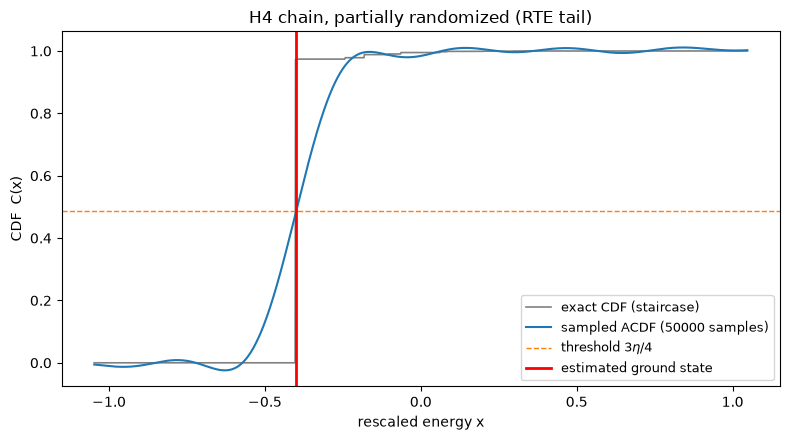

In [25]:
xgrid = np.linspace(-np.pi / 3, np.pi / 3, 1500)
plt.figure(figsize=(8, 4.5))
plt.plot(
    xgrid,
    exact_cdf(xgrid, evs_h4, p_h4),
    color="grey",
    lw=1.2,
    label="exact CDF (staircase)",
)
plt.plot(xgrid, G_h4(xgrid), "C0-", lw=1.5, label=f"sampled ACDF ({M_H4} samples)")
plt.axhline(0.75 * ETA_H4, color="C1", ls="--", lw=1, label=r"threshold $3\eta/4$")
plt.axvline(x_star_h4, color="red", lw=2, label="estimated ground state")
plt.xlabel("rescaled energy x")
plt.ylabel("CDF  C(x)")
plt.title("H4 chain, partially randomized (RTE tail)")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Appendix A: Precision, confidence, and the parameters

To leading order the two costs are **separate** ($\eta$ enters both):

* **Precision $\varepsilon$ ↔ band limit `D`.** The largest mode $k=D$ is the longest evolution time, and $\delta\propto1/D$ (Heisenberg); the overlap enters only through a logarithm. Finer precision means **deeper circuits**.
* **Confidence ↔ samples.** The error of $\bar G(x)$ falls as $1/\sqrt{M}$, at **fixed depth**. $M=O(\eta^{-2}\log^2 d\cdots)$, so a small overlap costs samples, not precision.
* **Overlap and threshold.** The paper only requires $\eta\le p_0$; we use the threshold $\tfrac34\eta$, and our choice $\eta\approx\tfrac23p_0$ is a heuristic that puts this threshold at the centre of the smoothed first jump, which removes the bias of the estimate for a wide step; a smaller $\eta$ costs more samples ($\propto\eta^{-2}$), and a larger one must stay below $p_0$.
* **Randomized evolution.** $B_k=B(\theta)^{rk/\zeta}$ inflates the variance by $B_k^2$ but leaves the signal unbiased; `R_TAIL` sets both the circuit size and how well one random circuit represents the average.

**Knobs:** `D_*`/`BETA_*` (precision), `M` (confidence), `ETA_*` (overlap bound), `N_DET` (head/tail split), `ZETA` (Trotter step of the head), `R_TAIL` (random terms per step: depth vs samples), `R_CIRC` (circuits per $k$).

## Appendix B: How loose is the Trotter bound?

For the TFIM we can compare the bound of Hagan & Wiebe [[13]](#ref-hagan) used in Example 1 with the actual error of the second-order formula (the symmetric splitting over the Pauli terms, emulated with matrices), as a function
of the repetitions $r$. This check uses the exact (classically computed) solution, so it is only possible for small problems, and it is not needed to run the algorithm:
* the operator-norm error of one step $e^{-i\tilde H}$, against the error that the bound guarantees, $\tfrac{2^5}{3}\gamma_2/r^2$ (with $\gamma_2$ the nested-commutator sum of `reps_from_err_bound`);
* the quantity that matters for phase estimation: the shift of the **ground-state energy**, $E_0^{\rm eff}-E_0$, where $e^{-iE^{\rm eff}}$ are the eigenvalues of the Trotter step (in Ha, to be compared with `EPS_HA`).

In [26]:
import scipy.linalg as sla

mat_tfim = hamiltonian_to_matrix(ham_tfim)  # rescaled TFIM matrix (reference only)

r_unit = reps_from_err_bound(
    ham_tfim, 1.0
)  # the bound's repetitions for unit error: the error it guarantees at r repetitions is (r_unit / r)^2
pauli_terms = [
    (
        t.coefficient,
        hamiltonian_to_matrix(
            SparsePauliOp(
                terms=[SparsePauliTerm(paulis=t.paulis, coefficient=1.0)],
                num_qubits=ham_tfim.num_qubits,
            )
        ),
    )
    for t in ham_tfim.terms
    if any(q.pauli != PauliEnum.I for q in t.paulis)
]


def strang_step(t):
    """Second-order (symmetric) splitting of e^{-i t H_s} over the Pauli terms."""
    first, second = np.eye(2**ham_tfim.num_qubits, dtype=complex), np.eye(
        2**ham_tfim.num_qubits, dtype=complex
    )
    for c, M in pauli_terms:
        first = sla.expm(-1j * c * M * t / 2) @ first
    for c, M in reversed(pauli_terms):
        second = sla.expm(-1j * c * M * t / 2) @ second
    return second @ first


U_exact = sla.expm(-1j * mat_tfim)
E_exact = np.linalg.eigvalsh(mat_tfim)
print(
    " r | operator-norm error of one step | error guaranteed by the bound | ground-state energy shift (Ha)"
)
for r in (1, 2, trotter_reps, 8, int(np.ceil(reps_bound))):
    U_trotter = np.linalg.matrix_power(strang_step(1.0 / r), r)
    err = np.linalg.norm(U_trotter - U_exact, 2)
    E_eff = np.sort(
        -np.angle(np.linalg.eigvals(U_trotter))
    )  # U_trotter = e^{-i H_eff}: the eigenphases are the rescaled energies
    print(
        f"{r:2d} | {err:.2e} | {(r_unit / r) ** 2:.2e} | {abs(E_eff[0] - E_exact[0]) / scale_tfim:.2e}"
    )

 r | operator-norm error of one step | error guaranteed by the bound | ground-state energy shift (Ha)
 1 | 7.78e-02 | 5.05e+01 | 1.33e-02
 2 | 1.95e-02 | 1.26e+01 | 3.29e-03
 4 | 4.87e-03 | 3.16e+00 | 8.19e-04
 8 | 1.22e-03 | 7.89e-01 | 2.05e-04
88 | 1.01e-05 | 6.52e-03 | 1.69e-06


## Appendix C: Parameter values: the paper's assumptions and our choices

The demo values used in the examples are relaxed. The table compares each knob with what the guarantees of Lin & Tong [[4]](#ref-lintong) ask for. The subsections below explain where each value comes from, marked as coming from the paper [[4]](#ref-lintong) (or Ref. [[6]](#ref-gunther) for Example 2) or as ours.

| knob | paper's requirement | what to change to get there |
|---|---|---|
| `D`, `BETA` | $d=O(\delta^{-1}\log(\delta^{-1}\eta^{-1}))$ so that $\tilde C$ is within $\eta/8$ of $C$ at shift $\delta$ | increase `D` (with `BETA` $=D^2/10$) until $\tilde C$ is within $\eta/8$ of $C$ at shift $\delta$ (checkable against the exact CDF for a small system) |
| `ETA` | a lower bound $\eta\le p_0$ (the only requirement of the paper) | use the best known lower bound on $p_0$; our $\eta\approx\tfrac23p_0$ is a heuristic for the demo, not a requirement |
| `M` | $M=O(\eta^{-2}\log^2 d\,(\log\log\delta^{-1}+\log\vartheta^{-1}))$ for the certified search of the paper; $O(\eta^{-2}\log^2d\,\log(\delta^{-1}\vartheta^{-1}))$ for our threshold estimate (Appendix D) | `sample_budget` gives the worst-case value; increase towards it until the result is stable across seeds |
| `EPS_HA` | the target precision $\varepsilon$ (the estimate is within $\delta=\varepsilon\cdot$ scale in rescaled units) | — |

### Number of samples $M$ (`sample_budget`)

The bound $M\ge256A^2\eta^{-2}\ln(2n_{\rm grid}/\vartheta)$ is derived in Appendix D (ours; the failure probability $\vartheta=5\%$ is also our choice). Evaluated with the theoretical band limit $d$, it gives $M\approx2.3\times10^5$ for the TFIM of Example 1 and $M\approx6.5\times10^4$ for the $\mathrm H_4$ chain (smaller, because of its larger overlap, $M\propto\eta^{-2}$), against the relaxed $M=2\times10^4$ (TFIM) and $M=5\times10^4$ ($\mathrm H_4$) that we use.

### Overlap bound $\eta$

The paper only requires $\eta\le p_0$. Our choice $\eta\approx\tfrac23p_0$ is a heuristic: the filter is symmetric, $F(0)=\tfrac12$, so at the centre of an isolated jump of height $p_0$ the ACDF is $\approx p_0/2$, and the threshold $\tfrac34\eta$ equals $p_0/2$ exactly when $\eta=\tfrac23p_0$.
Then the crossing of Eq. (4) is the centre of the smoothed step, with no bias even when the step is wide. With $\eta=p_0$ one needs $(3/2)^2\approx2.25$ times fewer samples ($M\propto\eta^{-2}$), but the crossing moves to $75\%$ of the jump. In the regime of the theory (step width $\lesssim\delta$) this offset stays within the guaranteed error $\delta$; with the relaxed $d$ it does not, which is why we use $\tfrac23p_0$.
The heuristic fails for a small overlap or for excited states close to the ground state, where the ACDF at the first jump is not $p_0/2$.

### Band limit $d$ and smoothing $\beta$

* $d$ (paper): $d=\mathcal O(\delta^{-1}\log(\delta^{-1}\eta^{-1}))$ with unspecified constants; the numerics of Ref. [[4]](#ref-lintong) use $d=4/\delta$. For the TFIM with $\varepsilon=0.01$ Ha both are of order $10^3$ ($\approx600$ and $\approx930$), and we checked that $d=600$ with $\beta=d^2/10$ satisfies the condition $\max|\tilde C-C|\le\eta/8$ at shift $\delta$ (gap $0.006$ against the allowed $0.0375$).
  We use $d=60$ (TFIM) and $d=18$ (H4) to keep the evolution times short: our choice, with the guarantee lost.
* $\beta$ (ours): the smoothing of the von Mises filter sets the width of the step, about $1.3/\sqrt\beta$, but a large $\beta$ makes the truncated series ring. Measured at $d=60$:

  | $\beta$ | 120 | 240 | 360 ($=d^2/10$) | 480 | 1000 |
  |---|---|---|---|---|---|
  | step width (10–90%) | 0.117 | 0.083 | 0.071 | 0.065 | 0.056 |
  | ringing (max deviation from the step) | 0.0002 | 0.0016 | 0.0030 | 0.0041 | 0.0067 |

  So $\beta=d^2/10$ gives a step of width $\approx4/d$ with ringing below $1\%$. A smaller $\beta$ such as $2d$ gives a much wider step: on the TFIM it never reached the $\eta/8$ condition, even at $d=930$.

### Other choices (ours)

* **Rescaling margin $0.9$:** the paper requires $\tau\|H\|<\pi/3$. The first jump is searched for in $(-\pi/3,\pi/3)$, and must lie strictly inside it, at least $\delta$ from the edges; any factor below 1 works for a small enough $\delta$.
* **Target precision $\varepsilon=0.01$ Ha** (`EPS_HA`): a demonstration value, a few times coarser than chemical accuracy ($1.6$ mHa).
* **Trotter safety factor 25:** reduces the repetitions from the worst-case $87$ to $4$, where the actual error is already below the target (see Appendix B).
* **`R_TAIL` $=4$:** the number of random terms per step (see the section on depth, samples and random circuits). It gives $B_D-1\approx D\zeta\lambda_R^2/r\approx0.09$, small enough for one random circuit per $k$, while keeping the tail short.
* **`N_DET` $=79$:** the 79 largest of the 132 Pauli terms of the tapered Hamiltonian (about $60\%$) form the head. It was chosen by hand and not optimized: a larger head costs more Trotter factors, a smaller one gives a larger tail weight $\lambda_R$ and hence more rounds $r\propto\lambda_R^2$.
* **`ZETA` $=1$:** one step per $U$, so that $S(\zeta)\approx U$. The symmetric splitting of the head shifts the ground-state energy by about $0.46$ mHa at $\zeta=1$, $0.12$ mHa at $\zeta=\tfrac12$ and $0.03$ mHa at $\zeta=\tfrac14$ (computed with exact matrices and an exact tail; it falls as $\zeta^2$), far below the target $10$ mHa. A smaller $\zeta$ multiplies the number of steps, and hence the circuit depth, by $1/\zeta$.
* **`N_RTE_MAX` $=4$:** the weight of orders $n\ge4$ is negligible for our $\theta$ (the probability of $n=2$ is about $\theta^2/2\approx6\times10^{-4}$), so the truncation is harmless.
* **`R_CIRC` $=1$:** one random circuit per $k$, the cheapest option; the error of reusing it is kept small by `R_TAIL`.

## Appendix D: Guarantees of the threshold estimate, and the certified search of Lin & Tong

### Why the threshold estimate is accurate (our original derivation, not from the paper)

**1. Two error budgets.** Let $\epsilon_F$ be the accuracy of the filter, $|F-H|\le\epsilon_F$ outside $[-\delta,\delta]$ (Eq. (7) of Ref. [[4]](#ref-lintong); not to be confused with the energy precision $\varepsilon$, although the paper uses the same symbol for both). Eq. (9) of Ref. [[4]](#ref-lintong) then gives
$$ C(x-\delta)-\epsilon_F\ \le\ \tilde C(x)\ \le\ C(x+\delta)+\epsilon_F . $$
As in Sec. 5 of the paper we take $\epsilon_F=\eta/8$, which fixes $d=\mathcal O(\delta^{-1}\log(\delta^{-1}\eta^{-1}))$ through its Lemma 6. Suppose, in addition, that the sampling error is $|\bar G-\tilde C|<\eta/8$ at every point of the search grid. The two errors add up to less than $\eta/4$, and
* for $x<\tau\lambda_0-\delta$: $C(x+\delta)=0$, so $\tilde C(x)\le\eta/8$ and $\bar G(x)<\eta/4$; no threshold $\ge\eta/4$ is crossed there;
* at $x=\tau\lambda_0+\delta$: $C(x-\delta)\ge p_0\ge\eta$, so $\tilde C(x)\ge\tfrac78\eta$ and $\bar G(x)>\tfrac34\eta$; every threshold $\le\tfrac34\eta$ has been crossed.

Hence $|x^\star-\tau\lambda_0|\le\delta$ (up to the grid spacing $\delta/10$) for any threshold in $[\eta/4,\tfrac34\eta]$, including the $\eta/2$ of the paper's numerics and our $\tfrac34\eta$. The condition must hold at **every** grid point, since a single noisy point to the left of the jump would trigger an early crossing.

**2. Each sample is bounded.** One sample at a drawn mode $k$, with outcomes $X,Y\in\{\pm1\}$, is (Eq. (3) folded to $k>0$, as in `acdf_estimate`)
$$ G=\tfrac12+A\,\big(\sin(kx)\,X+\cos(kx)\,Y\big). $$
Since $|\sin(kx)X+\cos(kx)Y|\le\sqrt2$, every sample lies in an interval of width $w=2\sqrt2A$.

**3. Hoeffding's inequality at one point.** For the mean of $M$ independent samples confined to an interval of width $w$, $\Pr\big[|\bar G-\tilde C|\ge t\big]\le2\exp(-2Mt^2/w^2)$. With $w^2=8A^2$ and $t=\eta/8$,
$$ \Pr\big[|\bar G(x)-\tilde C(x)|\ge\eta/8\big]\ \le\ 2\exp\!\Big(-\frac{M\eta^2}{256A^2}\Big). $$

**4. Union bound over the grid.** The search evaluates $\bar G$ at $n_{\rm grid}=(2\pi/3)/(\delta/10)$ points. The probability that any of them fails is at most $n_{\rm grid}$ times the bound above, and requiring it to be at most $\vartheta$ gives
$$ 2n_{\rm grid}\,e^{-M\eta^2/(256A^2)}\le\vartheta\quad\Longleftrightarrow\quad M\ \ge\ \frac{256A^2}{\eta^2}\,\ln\frac{2n_{\rm grid}}{\vartheta}, $$
the bound evaluated by `sample_budget`. With the RTE weights of Example 2 the samples are multiplied by up to $\max_kB_k$, and so is $A$.

**5. Scaling.** The filter coefficients decay as $|\hat F_k|\sim1/k$, so $A$ is a harmonic sum, $A=\mathcal O(\log d)$; and $n_{\rm grid}\propto\delta^{-1}$. Hence $M=\mathcal O\big(\eta^{-2}\log^2d\,\log(\delta^{-1}\vartheta^{-1})\big)$.
Compared with the certified search below, the sample cost differs by a single logarithmic factor ($\log\delta^{-1}$ instead of $\log\log\delta^{-1}$, since the certified search checks only $\mathcal O(\log\delta^{-1})$ points); the maximal evolution time $\tau d$ is unchanged, so the estimate is still Heisenberg-limited.

### The certified search of Lin & Tong

Lin & Tong look for a point $x^\star$ with $C(x^\star+\delta)>\eta/2$ and $C(x^\star-\delta)<\eta$ (Problem 1, Sec. 4 of Ref. [[4]](#ref-lintong)), which forces $|x^\star-\tau\lambda_0|\le\delta$. Since only the smooth $\tilde C$ is estimated, they reduce this to a decision at each point: with the filter accuracy $\epsilon_F=\eta/8$ (Sec. 5), either $\tilde C(x)>\tfrac58\eta$, which implies $C(x+\delta)>\eta/2$, or $\tilde C(x)<\tfrac78\eta$, which implies $C(x-\delta)<\eta$.
* `CERTIFY(x)` (Algorithm 2): split the $M$ samples into $N_B$ batches of $N_S$, and decide by the majority of the batch averages $\bar G_r(x)$ compared with the midpoint $\tfrac34\eta$.
* `INVERT CDF` (Algorithm 1): bisect $(-\pi/3,\pi/3)$ with `CERTIFY` at the shifts $\tfrac23\delta$, keeping $C(x_0)<\eta$ and $C(x_1)>\eta/2$, until the interval is at most $2\delta$ wide, after $L=\mathcal O(\log\delta^{-1})$ steps. (The prose of Sec. 5 reads $x_0\leftarrow x+\tfrac23\delta$; Algorithm 1 has $x_0\leftarrow x-\tfrac23\delta$, which is the update that keeps $C(x_0)<\eta$.)
* Each batch must err with probability at most $\tfrac14$ (Chebyshev's inequality: $N_S=\mathcal O(\eta^{-2}\log^2d)$), and the majority vote over $N_B=\mathcal O(\log(L/\vartheta))$ batches makes all the $L$ steps succeed with probability at least $1-\vartheta$, so $M=\mathcal O\big(\eta^{-2}\log^2d\,(\log\log\delta^{-1}+\log\vartheta^{-1})\big)$ (Theorem 2). The same samples serve all the steps.

The thresholds are design choices: in a simplified discussion the paper remarks that the cutoff "can be any number between 0 and 1 times $\eta$".

## References
<a name="references"></a>

<a name="ref-nielsen"></a>[1] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press (2000).

<a name="ref-kitaev"></a>[2] A. Yu. Kitaev, *Quantum measurements and the Abelian stabilizer problem*, [arXiv:quant-ph/9511026](https://arxiv.org/abs/quant-ph/9511026) (1995).

<a name="ref-babbush"></a>[3] R. Babbush, C. Gidney, D. W. Berry, N. Wiebe, J. McClean, A. Paler, A. Fowler, and H. Neven, *Encoding Electronic Spectra in Quantum Circuits with Linear T Complexity*, Phys. Rev. X 8, 041015 (2018).

<a name="ref-lintong"></a>[4] L. Lin and Y. Tong, *Heisenberg-Limited Ground-State Energy Estimation for Early Fault-Tolerant Quantum Computers*,
[PRX Quantum 3, 010318 (2022)](https://journals.aps.org/prxquantum/abstract/10.1103/PRXQuantum.3.010318).

<a name="ref-wbc"></a>[5] K. Wan, M. Berta, and E. T. Campbell, *Randomized Quantum Algorithm for Statistical Phase Estimation*,
[Phys. Rev. Lett. 129, 030503 (2022)](https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.129.030503).

<a name="ref-gunther"></a>[6] J. Günther, F. Witteveen, A. Schmidhuber, M. Miller, M. Christandl, and A. W. Harrow, *Phase Estimation with Partially Randomized Time Evolution*,
[arXiv:2503.05647](https://arxiv.org/abs/2503.05647) (PRX Quantum 7, 020332 (2026)).

<a name="ref-ding"></a>[7] Z. Ding and L. Lin, *Even shorter quantum circuit for phase estimation on early fault-tolerant quantum computers with applications to ground-state energy estimation*, PRX Quantum 4, 020331 (2023).

<a name="ref-obrien"></a>[8] T. E. O'Brien, B. Tarasinski, and B. M. Terhal, *Quantum phase estimation of multiple eigenvalues for small-scale (noisy) experiments*, New J. Phys. 21, 023022 (2019).

<a name="ref-kimmel"></a>[9] S. Kimmel, G. H. Low, and T. J. Yoder, *Robust calibration of a universal single-qubit gate set via robust phase estimation*, Phys. Rev. A 92, 062315 (2015).

<a name="ref-ni"></a>[10] H. Ni, H. Li, and L. Ying, *On low-depth algorithms for quantum phase estimation*, Quantum 7, 1165 (2023).

<a name="ref-wiebe"></a>[11] N. Wiebe and C. Granade, *Efficient Bayesian phase estimation*, Phys. Rev. Lett. 117, 010503 (2016).

<a name="ref-somma"></a>[12] R. D. Somma, *Quantum eigenvalue estimation via time series analysis*, New J. Phys. 21, 123025 (2019).

<a name="ref-hagan"></a>[13] M. Hagan and N. Wiebe, *Composite quantum simulations*, Quantum 7, 1181 (2023).